# 02 Explore, estimate and explain weather associations
 What is the association between daily Citi Bike trip starts and temperature or precipitation after accounting for month and day of week?
 The measured outcome is recorded starts. The fitted contrasts have an observational interpretation.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from model_analysis import run
from make_figures import run as draw
OUT=Path('results')
model=run(OUT,Path('data/raw/nyc_weather_2023.csv'))
draw(OUT)
display(pd.DataFrame(model['models']).T)

,n,p,r2,adjusted_r2,mae,rmse,condition_number
simple,365.0,4.0,0.672023,0.669298,14857.827368,18482.275800,3.438748
calendar,365.0,18.0,0.640764,0.623165,13887.820614,19342.984977,13.550743
adjusted,365.0,22.0,0.792475,0.779770,10387.573250,14701.741419,50.273942
adjusted_amount,365.0,21.0,0.798871,0.787177,10163.984875,14473.429180,49.916278


## Model and interpretation
 Primary OLS uses the centered high–low midpoint, its square, precipitation groups, weekday and month.
 The calendar-only model provides a nested reference. The continuous PRCP model uses raw units.
 The covariance uses Bartlett HAC over seven calendar days and intervals use the asymptotic normal reference.
 Each temperature panel uses the 10th to 90th percentiles of recorded-zero dates in that month. The fitted mean averages over the weekdays of those same dates. The model still uses all 365 dates.

In [2]:
for name in ('temp_50_to_60','temp_70_to_80','measurable_vs_zero','trace_vs_zero'):
    print(name,model[name])
display(pd.read_csv(OUT/'coefficients.csv').query("model=='adjusted' and term in ['temp10f','temp10f_squared','trace','measurable']"))

temp_50_to_60 {'estimate': 12899.89606746905, 'lower': 10437.327209477327, 'upper': 15362.464925460772, 'se': 1256.4357699509542}
temp_70_to_80 {'estimate': 10813.665883181151, 'lower': 5781.652289837318, 'upper': 15845.679476524983, 'se': 2567.401050751807}
measurable_vs_zero {'estimate': -21724.918517694034, 'lower': -26514.769155614056, 'upper': -16935.06787977401, 'se': 2443.8462521259344}
trace_vs_zero {'estimate': -3142.009752028897, 'lower': -6390.688494613634, 'upper': 106.66899055584099, 'se': 1657.519611691797}


,model,term,estimate,lower,upper,se
40,adjusted,temp10f,12378.338521,9481.812047,15274.864996,1477.846786
41,adjusted,temp10f_squared,-521.557546,-1432.346328,389.231236,464.696693
42,adjusted,trace,-3142.009752,-6390.688495,106.668991,1657.519612
43,adjusted,measurable,-21724.918518,-26514.769156,-16935.067880,2443.846252


## Daily Citi Bike starts in 2023
365 NYC-release dates

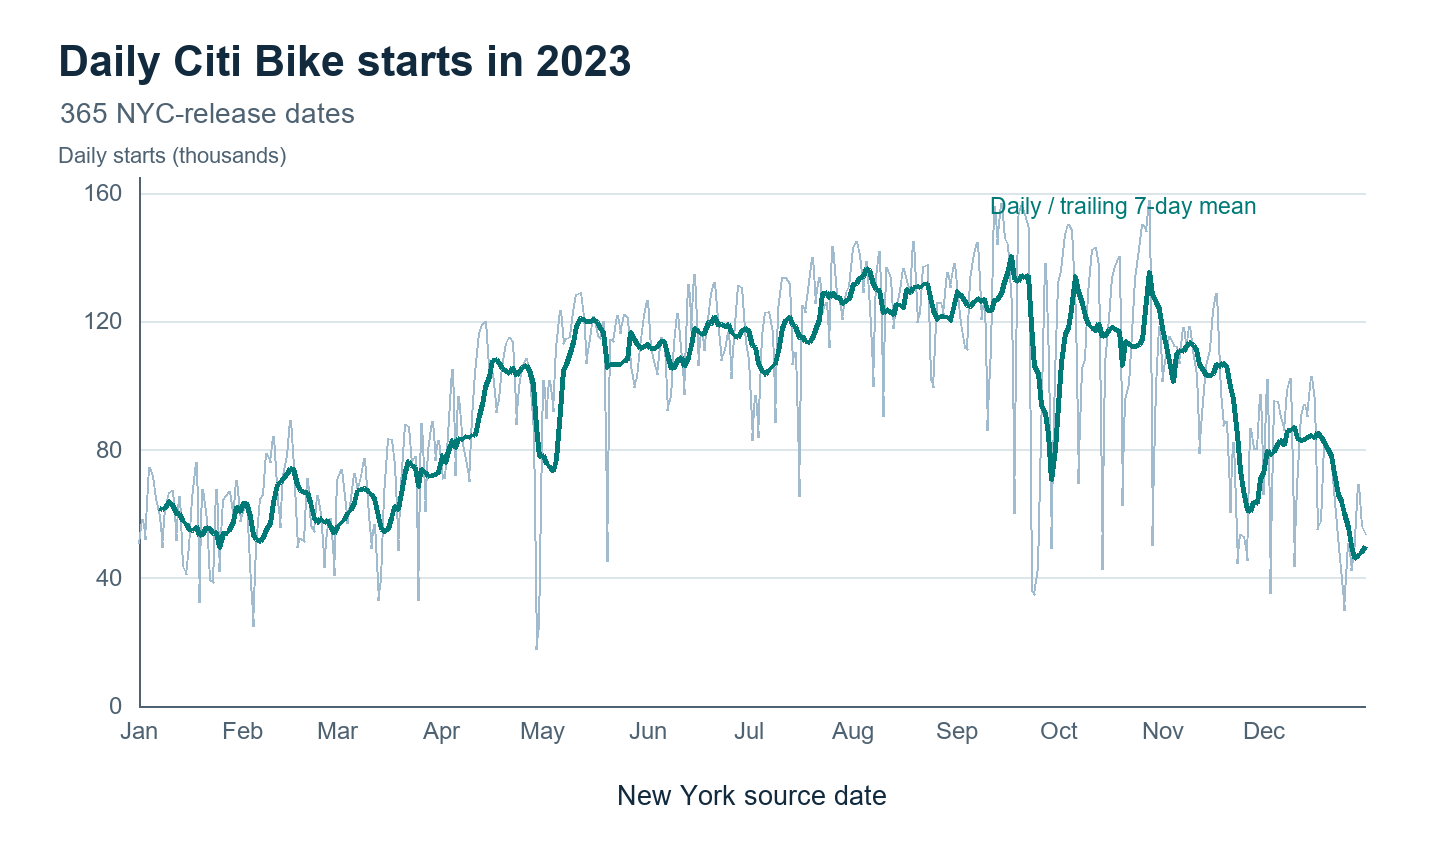

In [3]:
display(Image(filename=str(OUT/'figures/daily.png')))

- **Truthful** Exact daily totals and a labeled trailing 7-day mean.
- **Functional** Monthly ticks and rides in thousands show variation through the year.
- **Beautiful** A muted daily series and thick teal mean avoid competing colors.
- **Insightful** Seasonal structure motivates adjustment for month and weekday.

## Warmer dates tend to have more starts
Raw data before calendar adjustment

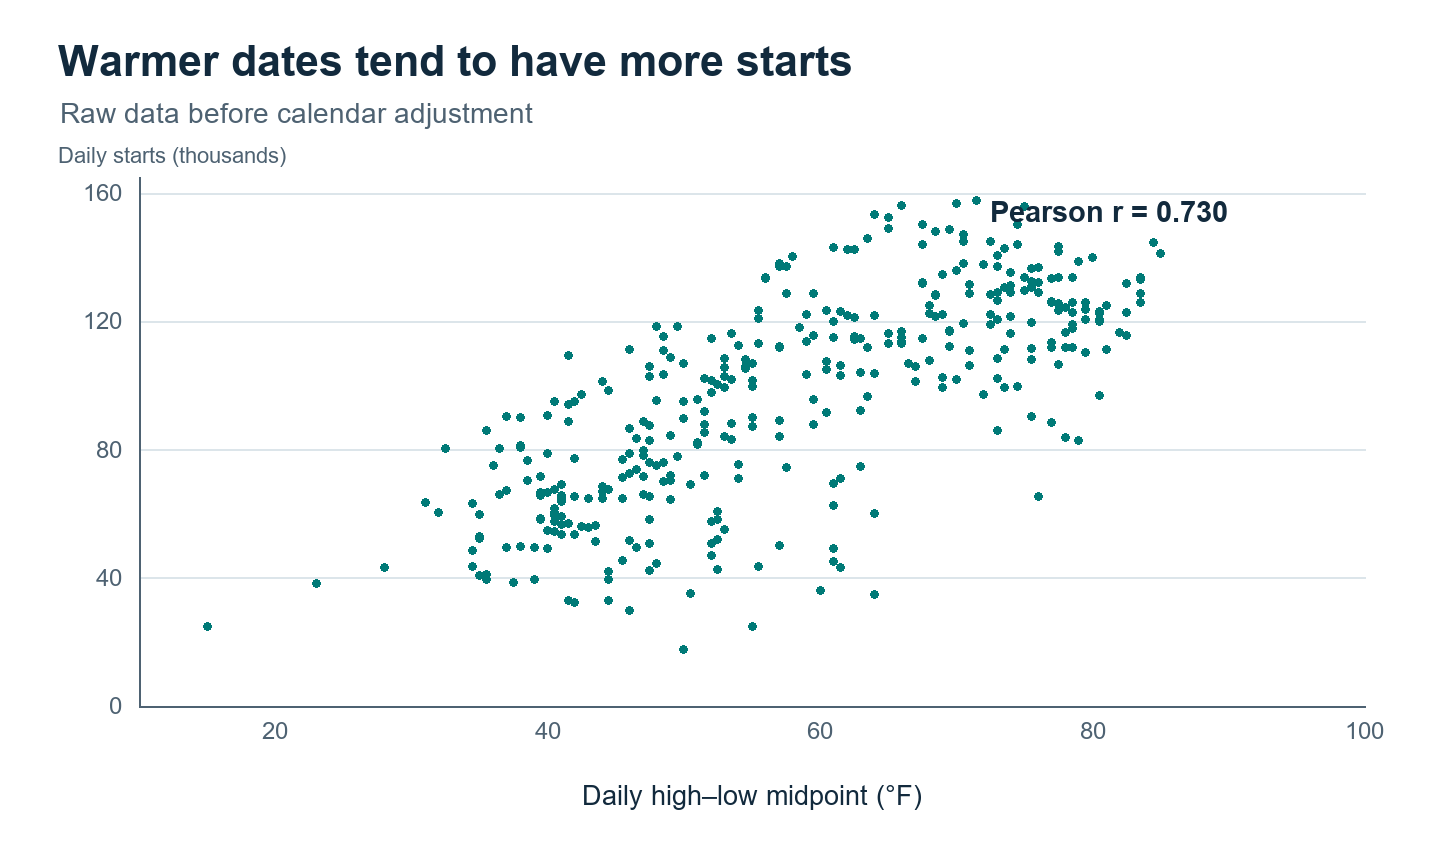

In [4]:
display(Image(filename=str(OUT/'figures/scatter.png')))

- **Truthful** Every point is one date. Pearson r is a descriptive statistic.
- **Functional** The axes show the temperature proxy in °F and starts in thousands.
- **Beautiful** Small teal dots make overlap visible without obscuring the cloud.
- **Insightful** The upward pattern motivates an adjusted comparison.

## Fewer starts on measurable precipitation days
Central Park recorded groups

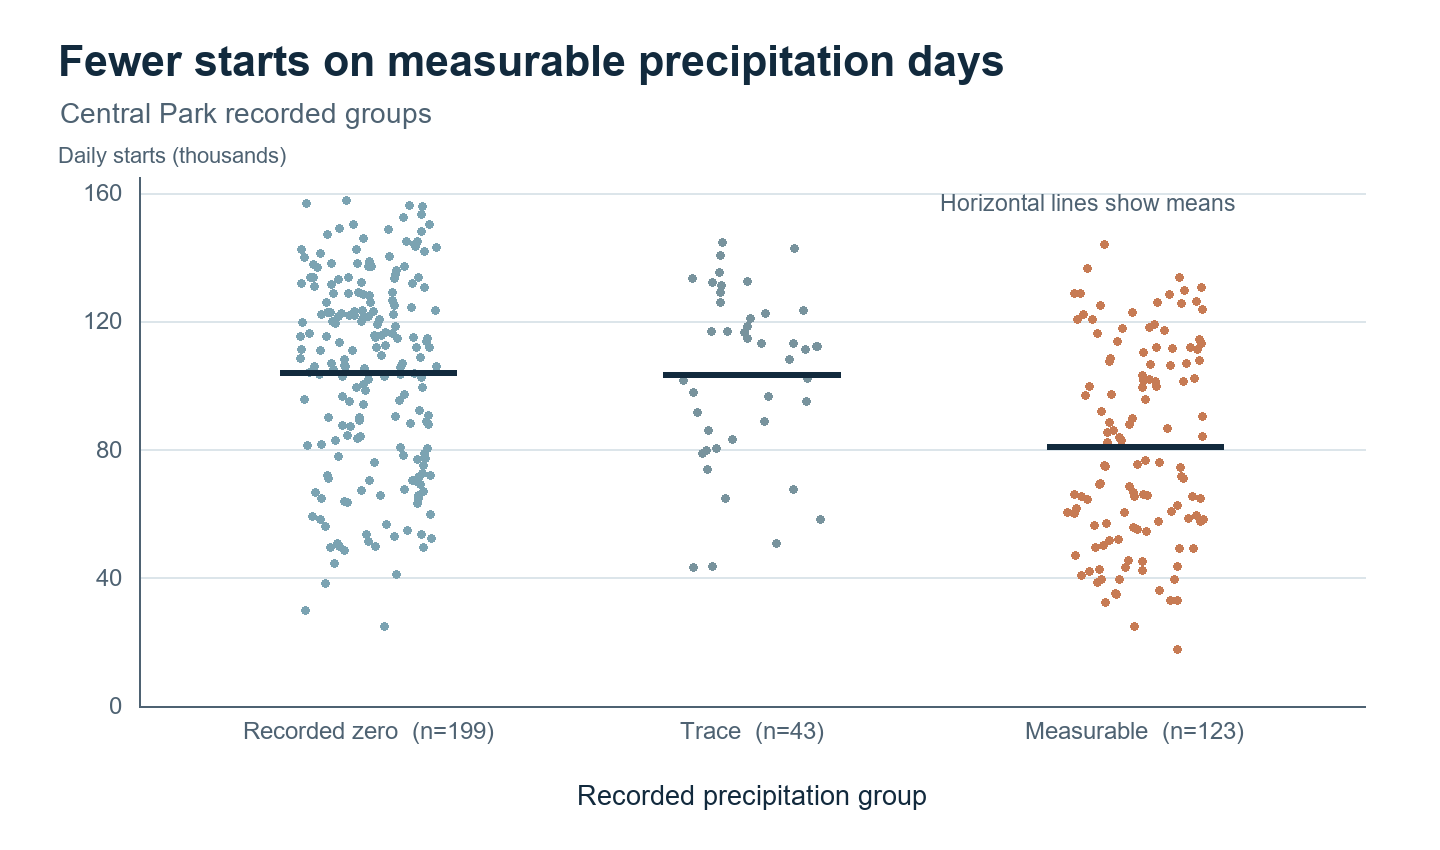

In [5]:
display(Image(filename=str(OUT/'figures/precip.png')))

- **Truthful** All 365 days and group sizes are shown, together with group means.
- **Functional** Recorded zero, trace and measurable days have separate labels.
- **Beautiful** A common scale and sparse marks keep the comparison readable.
- **Insightful** Trace and recorded zero look similar descriptively, while measurable days are lower.

## Calendar-adjusted temperature by month
Central 80% of recorded-zero temperatures within each month

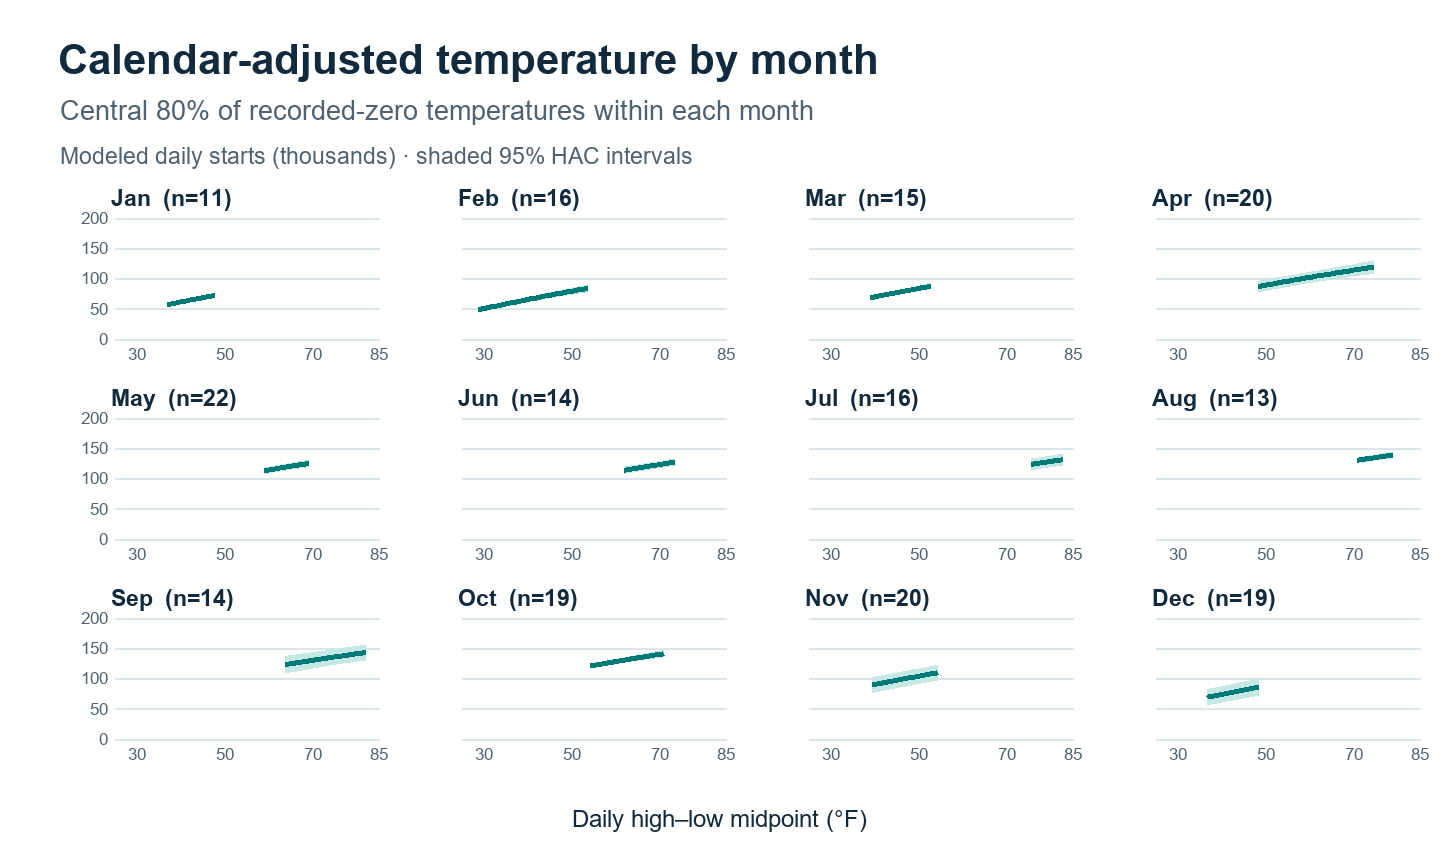

In [6]:
display(Image(filename=str(OUT/'figures/curve.png')))

- **Truthful** Each panel uses its month's observed range and shows pointwise 95% HAC intervals.
- **Functional** Shared axes compare the °F proxy and modeled mean starts across months.
- **Beautiful** Teal curves and light bands distinguish estimates from uncertainty.
- **Insightful** Monthly panels show where the annual model has local temperature support.

## Residuals still vary across the year
Adjusted model, ordered by calendar date

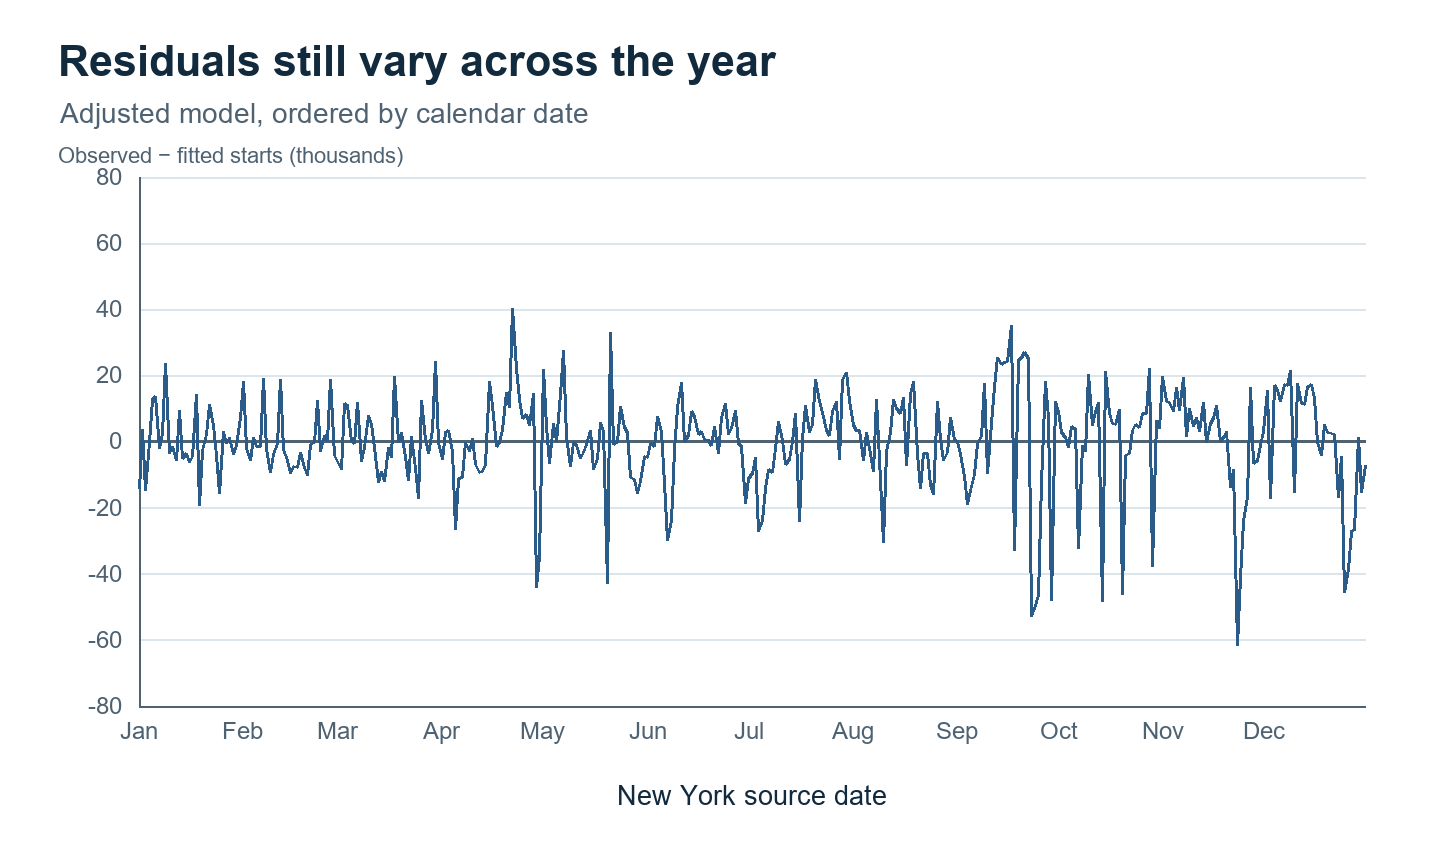

In [7]:
display(Image(filename=str(OUT/'figures/residual.png')))

- **Truthful** All 365 residuals are shown relative to zero.
- **Functional** The time axis helps locate unusual periods and the sign of errors.
- **Beautiful** A thin baseline and a single data color keep attention on departures.
- **Insightful** Runs above and below zero motivate daily dependence checks.

## Daily starts vary by day of week
Descriptive medians and interquartile ranges

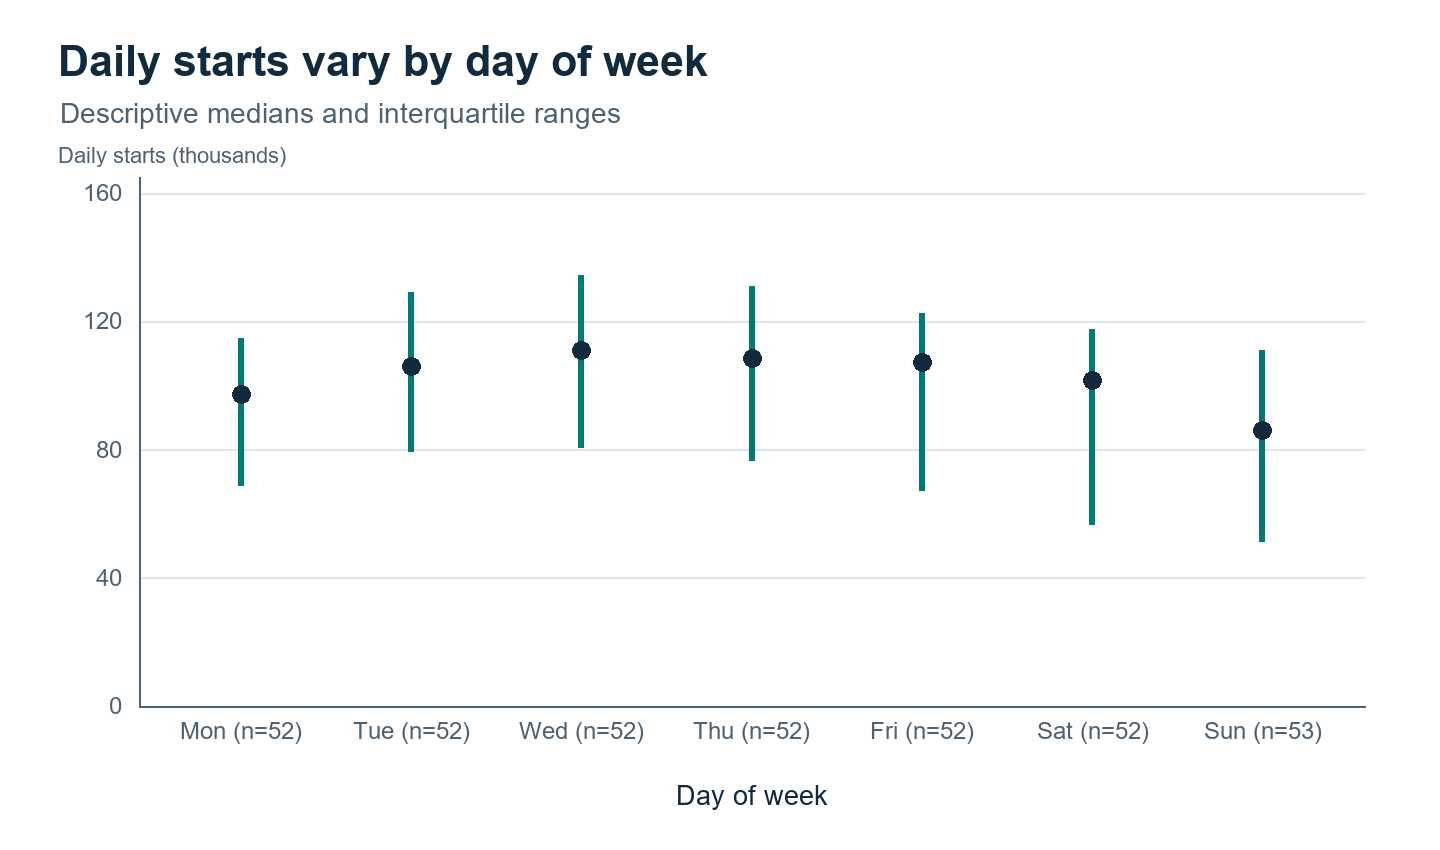

In [8]:
display(Image(filename=str(OUT/'figures/weekday.png')))

- **Truthful** The line spans the middle 50% of dates, not a confidence interval.
- **Functional** Days follow calendar order and each sample size is printed.
- **Beautiful** A shared scale and sparse marks make groups easy to compare.
- **Insightful** Different day profiles motivate separate weekday controls.

## Temperature and precipitation together
Raw median starts by weather group and temperature band

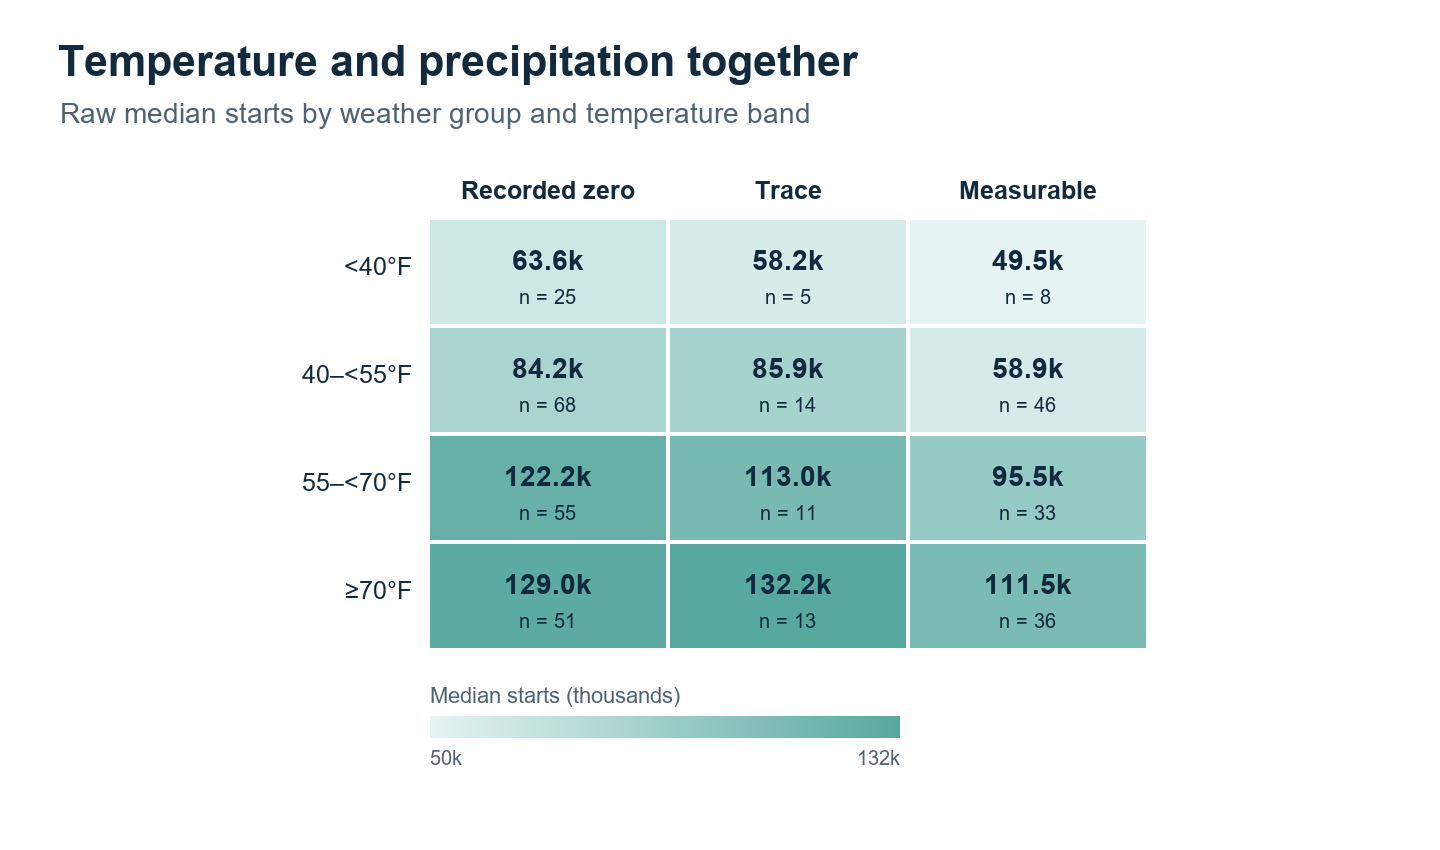

In [9]:
display(Image(filename=str(OUT/'figures/joint.png')))

- **Truthful** Sample sizes appear in every cell. Medians are hidden when n < 5.
- **Functional** A common color scale and numerical labels show the median starts.
- **Beautiful** Muted shading leaves room for the cell labels.
- **Insightful** Readers can see which combinations have limited support before interpreting the raw differences.

## Adjusted changes in daily starts
Primary model contrasts, pointwise 95% HAC intervals

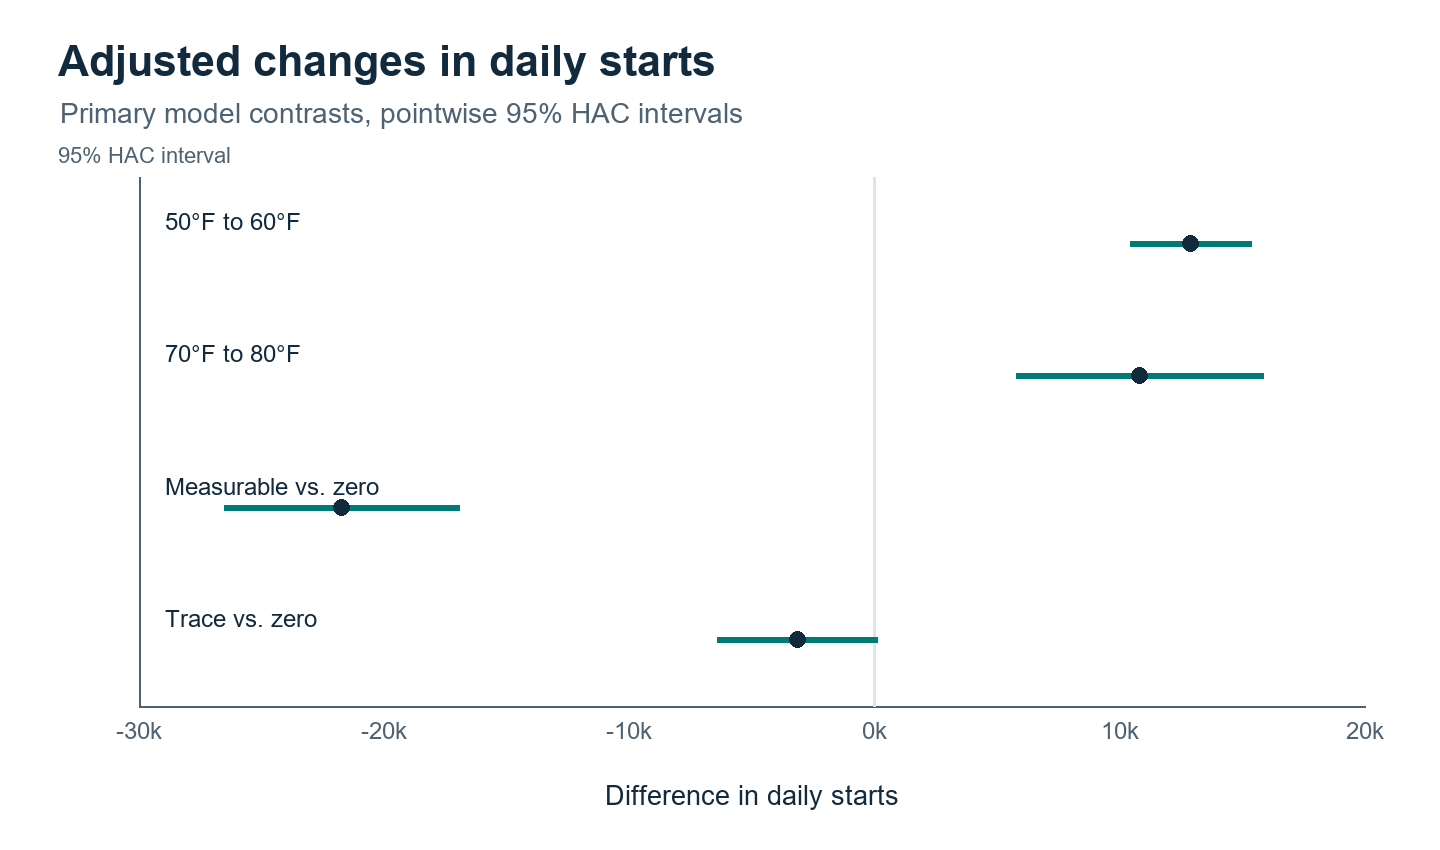

In [10]:
display(Image(filename=str(OUT/'figures/contrasts.png')))

- **Truthful** All plotted intervals come from the same primary model.
- **Functional** The zero line separates higher from lower modeled starts.
- **Beautiful** The chart uses one unit and simple interval marks.
- **Insightful** Readers can compare magnitudes and distinguish the less precise trace result.

## Robustness and limits
 Compare lag lengths, precipitation definitions, log outcome, snowfall and influential-date exclusions, coordinate coverage and LaGuardia.
 Specifications on different outcome scales have different coefficient meanings. Retain all dates in the main result.
 A single year, missing supply variables and weather measured at a station limit interpretation.

In [11]:
display(pd.read_csv(OUT/'sensitivity.csv').round(3))
display(pd.read_csv(OUT/'temperature_contrasts.csv').round(1))
support=pd.read_csv(OUT/'temperature_support.csv')
display(support.loc[support.supported, ['from_f','to_f','scope','month','near_from_n','near_to_n']])
print('Residual ACF',model['acf_lag1'],model['acf_lag7'])
print('Durbin–Watson',model['durbin_watson'])
print('Most influential dates',model['high_cook_dates'])

,specification,n,lag,r2,outcome_scale,temp_estimate,temp_lower,temp_upper,temp_se,precip_estimate,precip_lower,precip_upper,precip_se
0,Primary categories,365,7,0.792,trip starts,12899.896,10437.327,15362.465,1256.436,-21724.919,-26514.769,-16935.068,2443.846
1,HAC lag 3,365,3,0.792,trip starts,12899.896,10436.031,15363.762,1257.097,-21724.919,-25997.548,-17452.289,2179.953
2,HAC lag 14,365,14,0.792,trip starts,12899.896,10377.457,15422.335,1286.982,-21724.919,-27176.722,-16273.115,2781.583
3,Continuous PRCP (per raw CSV unit),365,7,0.799,trip starts,11600.995,8968.030,14233.960,1343.374,-23230.729,-32245.640,-14215.819,4599.528
4,Any positive recorded precipitation,365,7,0.792,trip starts,12881.756,10403.697,15359.815,1264.339,-21136.558,-25763.276,-16509.840,2360.614
5,Positive or trace (wet),365,7,0.765,trip starts,12835.344,10271.420,15399.269,1308.149,-16828.082,-21171.770,-12484.393,2216.208
6,Log daily starts,365,7,0.727,percent difference in modeled geometric mean o...,17.918,14.212,21.745,NaN,-23.287,-27.921,-18.356,NaN
7,Exclude four recorded snowfall days,361,7,0.791,trip starts,13087.912,10646.930,15528.894,1245.422,-22212.671,-27028.129,-17397.212,2456.912
8,Inside broad coordinate screen,365,7,0.792,trip starts,12900.784,10439.436,15362.132,1255.813,-21709.918,-26495.287,-16924.549,2441.560
9,Exclude three highest-Cook dates,362,7,0.814,trip starts,12257.212,9939.797,14574.627,1182.376,-21290.145,-25632.660,-16947.629,2215.610


,from_f,to_f,supported_months_all,supported_months_zero,support_month_count,estimate,lower,upper,se
0,30,40,2,NaN,1,14986.1,11332.0,18640.2,1864.4
1,40,50,"1,2,3,11,12","2,3,11,12",5,13943.0,11415.1,16470.9,1289.8
2,50,60,"4,5,10",4,3,12899.9,10437.3,15362.5,1256.4
3,60,70,"5,6,9,10","5,6,10",4,11856.8,8339.0,15374.5,1794.8
4,70,80,"8,9",NaN,2,10813.7,5781.7,15845.7,2567.4


,from_f,to_f,scope,month,near_from_n,near_to_n
1,30,40,All precipitation groups,2,2,6
24,40,50,All precipitation groups,1,12,8
25,40,50,All precipitation groups,2,6,2
26,40,50,All precipitation groups,3,13,5
34,40,50,All precipitation groups,11,7,11
35,40,50,All precipitation groups,12,9,10
37,40,50,Recorded zero,2,3,2
38,40,50,Recorded zero,3,6,3
46,40,50,Recorded zero,11,5,9
47,40,50,Recorded zero,12,9,4


Residual ACF 0.2911366558228111 -0.0330015972634816
Durbin–Watson 1.4145248749865889
Most influential dates [{'date': '2023-11-23', 'cook': 0.0424796316108641}, {'date': '2023-09-23', 'cook': 0.040087833177647116}, {'date': '2023-09-29', 'cook': 0.03306891710133053}]


The joint weather figure gives descriptive medians and counts. A formal interaction test would require a different model. The weekday ranges show the middle half of observed dates.
 The temperature support table requires each month to bracket both endpoints and have at least two observations within 2.5°F of each. This screen describes overlap at the month level. It is separate from the model fit and does not establish overlap within every weekday and precipitation combination.